# How sub-model states are initialized

Each sub-model's match states come from its medoid alone (`make_hmm()` → `compress()`):

1. `distance_profile()`: Euclidean distance between consecutive frames.
2. `top_k_switchpoints()`: the `max_switchpoints` largest local maxima of that profile, plus both ends, become anchors. One state per anchor.
3. `compress()`: k-means-like refinement. Each frame may only go to the states of its neighbouring anchors, but nothing keeps the assignment left to right.

In `cluster` mode the members are then aligned to these states (`align_to_states()`) and the emissions re-estimated, so the medoid's segmentation decides what every member frame is pooled into.

**Hypothesis:** the change-point segmentation isn't a good start. Peaks of a frame-to-frame distance are noisy, the number of states depends on how many peaks there are, and the assignment can go backwards, which a left-to-right sub-model can't do.

Alternatives, all with the **same number of states per medoid** as change-point unless noted, so only placement changes:

| name | what it does |
|---|---|
| `changepoint` | current: `top_k_switchpoints()` + `compress()` |
| `changepoint + seg. k-means` | change-point means, then left-to-right Viterbi re-segmentation until stable (keeps the anchors' idea, forces monotone) |
| `flat` | equal-length segments, no refinement (true flat start of the segmentation) |
| `flat + seg. k-means` | equal-length segments refined by left-to-right Viterbi re-segmentation (HTK `HInit` style) |
| `optimal` | the least-squares piecewise-constant segmentation into K pieces, exact by dynamic programming (offline change-point detection done globally instead of by local peaks) |
| `flat, max K` | equal-length segments with every sub-model at the cap, so the state count no longer depends on the peak count |

Everything else stays as in production: same clustering, `cluster` construction (`max_members` 5, `shrinkage` 10), same flank settings. All code lives in this notebook; the evaluation helpers are loaded from `ViterbiSubmodelTrainingEffect.ipynb`.

In [1]:
import os
import sys
import json
import pickle
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = os.path.abspath('..')
sys.path.insert(0, REPO)

import lib_phmm.phmm_utils as pu
from lib_phmm.compression import compress as changepoint_compress, distance_profile, top_k_switchpoints

# evaluation helpers (find-style decodes, held-out metrics, usage) from the sub-model training notebook
with open(os.path.join(REPO, 'analysis_notebooks', 'ViterbiSubmodelTrainingEffect.ipynb')) as f:
    _cells = json.load(f)['cells']
exec(next(''.join(c['source']) for c in _cells if 'def run_exemplar_sweep' in ''.join(c['source'])))

In [2]:
HANDLER_STATE      = os.path.join(REPO, 'motif', 'handler_state')
EMBEDDINGS_DIR     = os.path.join(HANDLER_STATE, 'motif_embeddings_cache')
EMBEDDINGS_VERSION = 'v2'
MODEL_PATH         = os.path.join(HANDLER_STATE, 'motif_extend_state', 'phmm_extended_cluster_mode.pkl')
CANDIDATES_PATH    = os.path.join(HANDLER_STATE, 'motif_extend_state', 'candidates.pkl')

# held-out recordings: same draw as the two Viterbi notebooks
SWEEP_HELDOUT_FRAMES = 80_000
SPLIT_SEED           = 0

# construction settings of the saved model (train-candidates defaults, variance=cluster)
MAX_MEMBERS = 5
SHRINKAGE   = 10.0
N_JOBS      = 4

# kmedoids is seeded from std::random_device, so the clustering is computed once and cached:
# every initialization below is built on the same clusters
CLUSTER_CACHE = os.path.join(HANDLER_STATE, 'motif_extend_state', f'state_init_clustering_split{SPLIT_SEED}.pkl')

In [3]:
with open(MODEL_PATH, 'rb') as f:
    model_record = pickle.load(f)
saved_hmm = model_record['hmm']
FLANK_DWELL = model_record['flank_dwell_frames']
FLANK_ALPHA = model_record['flank_alpha']
MAX_STATES_PER_SUBMODEL = max(saved_hmm.last_match)          # real states of the widest sub-model
MAX_SWITCHPOINTS = MAX_STATES_PER_SUBMODEL - 2               # top_k_switchpoints() adds both ends
print(f"saved model: {model_record['n_models']} sub-models, widest {MAX_STATES_PER_SUBMODEL} states "
      f"-> max_switchpoints {MAX_SWITCHPOINTS}, flank dwell {FLANK_DWELL:.1f}")

with open(CANDIDATES_PATH, 'rb') as f:
    exemplars = pickle.load(f)

embeddings, labels, names = [], [], []
for file_name in sorted(os.listdir(EMBEDDINGS_DIR)):
    if file_name.endswith(f'.{EMBEDDINGS_VERSION}.pkl') and not file_name.startswith('noise_embeddings'):
        with open(f"{EMBEDDINGS_DIR}/{file_name}", 'rb') as f:
            emb, classifications, step_samples, emb_sr = pickle.load(f)
            embeddings.append(np.asarray(emb))
            labels.append(np.asarray(classifications))
            names.append(file_name[:-len(f'.{EMBEDDINGS_VERSION}.pkl')])
STEP_SECONDS = step_samples / emb_sr

with open(f"{EMBEDDINGS_DIR}/noise_embeddings.v2.pkl", 'rb') as f:
    noise_embeddings, _ = pickle.load(f)
noise_pdf = fit_noise_model(np.asarray(noise_embeddings), n_components=6, var_scale=1.0)

order = [i for i in np.random.default_rng(SPLIT_SEED).permutation(len(embeddings)) if len(embeddings[i]) >= 1000]
heldout_idx = []
for i in order:
    if sum(len(embeddings[j]) for j in heldout_idx) >= SWEEP_HELDOUT_FRAMES:
        break
    heldout_idx.append(i)
heldout_sequences = [embeddings[i] for i in heldout_idx]
heldout_labels    = [labels[i] for i in heldout_idx]
heldout_names     = [names[i] for i in heldout_idx]

sources = match_exemplars_to_recordings(exemplars, embeddings, names)
heldout_exemplars = [e for e, s in zip(exemplars, sources) if s in heldout_names]
train_exemplars   = [e for e, s in zip(exemplars, sources) if s not in heldout_names]
print(f"held-out recordings: {heldout_names}")
print(f"train: {len(train_exemplars)} exemplars; held-out: {len(heldout_exemplars)} exemplars")

saved model: 694 sub-models, widest 22 states -> max_switchpoints 20, flank dwell 31.0


held-out recordings: ['08162401_EAGLE_TASCAM (jump 2)', '05102103_Manta', '07172102_Manta', '07232501_SKATE_TASCAM (jump 2)', '05232401_SKATE_TASCAM']
train: 7087 exemplars; held-out: 296 exemplars


## One clustering for all initializations

Unlike the saved model, the clustering here only sees the **training** exemplars, so the held-out exemplars are truly unseen by every model below, the change-point baseline included.

In [4]:
if os.path.exists(CLUSTER_CACHE):
    with open(CLUSTER_CACHE, 'rb') as f:
        medoid_ids, member_ids = pickle.load(f)
else:
    _, members_, medoid_ids = pu.filter_candidates_by_medoid(train_exemplars, return_members=True, return_ids=True)
    index_of = {id(e): i for i, e in enumerate(train_exemplars)}
    member_ids = [[index_of[id(m)] for m in cluster] for cluster in members_]
    with open(CLUSTER_CACHE, 'wb') as f:
        pickle.dump((medoid_ids, member_ids), f)

medoids = [train_exemplars[i] for i in medoid_ids]
members = [[train_exemplars[i] for i in cluster] for cluster in member_ids]
sizes = np.array([1 + len(m) for m in members])
print(f"{len(medoids)} medoids, cluster size median {np.median(sizes):.0f}, max {sizes.max()}; "
      f"{(sizes > 1 + MAX_MEMBERS).sum()} clusters have members beyond the {MAX_MEMBERS} used for construction")

100 medoids, cluster size median 6, max 2313; 45 clusters have members beyond the 5 used for construction


## The initializations

Each one has `compress()`'s signature, `(sequence, points) -> (assignment, means, variances)`, and is swapped in for it inside `make_hmm()`, so the rest of construction is untouched. `points` gives the change-point state count K, which every alternative except `flat, max K` reuses.

In [5]:
def segment_stats(seq, a, K):
    means = [seq[a == k].mean(axis=0) for k in range(K)]
    variances = [np.maximum(seq[a == k].var(axis=0), VAR_FLOOR) for k in range(K)]
    return means, variances


def flat_assignment(n, K):
    bounds = np.linspace(0, n, K + 1).round().astype(int)
    return np.repeat(np.arange(K), np.diff(bounds))


def segmental_kmeans(seq, a, K, n_iter=10):
    # left-to-right Viterbi re-segmentation (align_to_states) until the segmentation stops changing
    for _ in range(n_iter):
        means, variances = segment_stats(seq, a, K)
        new = pu.align_to_states(seq, np.array(means), np.array(variances))
        if np.array_equal(new, a):
            break
        a = new
    return a


def optimal_assignment(seq, K):
    # least-squares piecewise-constant segmentation into K pieces: cost[k][j] = best k+1 segments of seq[:j]
    n = len(seq)
    S = np.vstack([np.zeros(seq.shape[1]), np.cumsum(seq, axis=0)])
    Q = np.r_[0.0, np.cumsum((seq ** 2).sum(axis=1))]
    G = S @ S.T
    sq = np.diag(G)
    length = np.arange(n + 1)[None, :] - np.arange(n + 1)[:, None]
    with np.errstate(divide='ignore', invalid='ignore'):
        C = (Q[None, :] - Q[:, None]) - (sq[None, :] + sq[:, None] - 2 * G) / length   # SSE of seq[i:j]
    C[length <= 0] = np.inf
    cost, back = C[0], []
    for _ in range(1, K):
        total = cost[:, None] + C
        arg = total.argmin(axis=0)
        cost = total[arg, np.arange(n + 1)]
        back.append(arg)
    bounds = [n]
    for arg in reversed(back):
        bounds.append(arg[bounds[-1]])
    bounds = [0] + bounds[::-1]
    return np.repeat(np.arange(K), np.diff(bounds))


def init_changepoint(sequence, points):
    return changepoint_compress(sequence, points)


def init_changepoint_refined(sequence, points):
    _, mu, var = changepoint_compress(sequence, points)
    a = segmental_kmeans(sequence, pu.align_to_states(sequence, np.array(mu), np.array(var)), len(mu))
    return (a, *segment_stats(sequence, a, len(mu)))


def init_flat(sequence, points):
    a = flat_assignment(len(sequence), len(points))
    return (a, *segment_stats(sequence, a, len(points)))


def init_flat_kmeans(sequence, points):
    a = segmental_kmeans(sequence, flat_assignment(len(sequence), len(points)), len(points))
    return (a, *segment_stats(sequence, a, len(points)))


def init_optimal(sequence, points):
    a = optimal_assignment(sequence, len(points))
    return (a, *segment_stats(sequence, a, len(points)))


def init_flat_max_k(sequence, points):
    K = min(MAX_STATES_PER_SUBMODEL, len(sequence))
    a = flat_assignment(len(sequence), K)
    return (a, *segment_stats(sequence, a, K))


INITS = {
    "changepoint":                init_changepoint,
    "changepoint + seg. k-means": init_changepoint_refined,
    "flat":                       init_flat,
    "flat + seg. k-means":        init_flat_kmeans,
    "optimal":                    init_optimal,
    "flat, max K":                init_flat_max_k,
}


@contextmanager
def initialization(fn):
    original = pu.compress
    pu.compress = fn
    try:
        yield
    finally:
        pu.compress = original

## What the medoid segmentations look like

Per medoid, before any pooling:

- *K*: states.
- *monotone*: share of medoids whose assignment never goes back to an earlier state. A left-to-right sub-model can only follow a monotone one.
- *empty states*: states that got no frame, so they keep the anchor frame's value and the initial variance.
- *SSE / frame*: squared distance of each medoid frame to its state mean. Lower is a tighter fit of the medoid itself, not necessarily better generalization.
- *shortest state*: median over medoids of the shortest state's length in frames.

In [6]:
def segmentation_stats(init):
    rows = []
    for seq, _, _ in medoids:
        seq = np.asarray(seq)
        points = top_k_switchpoints(distance_profile(seq), MAX_SWITCHPOINTS)
        a, mu, _ = init(seq, points)
        K = len(mu)
        counts = np.bincount(a, minlength=K)
        rows.append({"K": K, "monotone": bool(np.all(np.diff(a) >= 0)), "empty states": int((counts == 0).sum()),
                     "SSE / frame": float(((seq - np.asarray(mu)[a]) ** 2).sum() / len(seq)),
                     "shortest state": int(counts[counts > 0].min())})
    return pd.DataFrame(rows)


segmentations = {name: segmentation_stats(init) for name, init in INITS.items()}
pd.DataFrame({name: {"mean K": d["K"].mean(), "monotone": d["monotone"].mean(),
                     "medoids with empty states": (d["empty states"] > 0).mean(),
                     "SSE / frame": d["SSE / frame"].mean(), "median shortest state": d["shortest state"].median()}
              for name, d in segmentations.items()}).T.round(3)

,mean K,monotone,medoids with empty states,SSE / frame,median shortest state
changepoint,9.78,0.71,0.0,0.152,1.0
changepoint + seg. k-means,9.78,1.00,0.0,0.152,1.0
flat,9.78,1.00,0.0,0.180,2.0
flat + seg. k-means,9.78,1.00,0.0,0.154,2.0
optimal,9.78,1.00,0.0,0.121,1.0
"flat, max K",16.86,1.00,0.0,0.056,1.0


medoid length: median 18, max 255 frames; mean share of medoid frames labelled NOISE 0.005


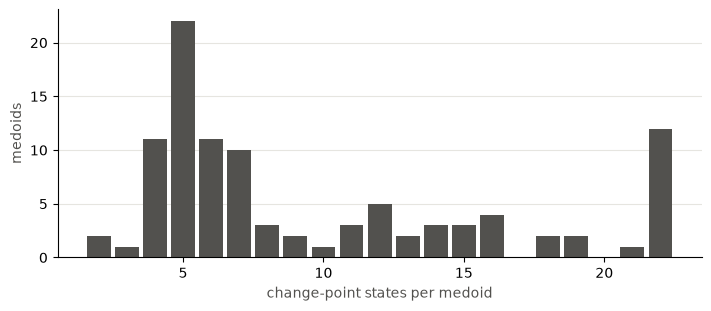

In [7]:
medoid_lengths = np.array([len(m[0]) for m in medoids])
noise_share = np.mean([np.mean(np.asarray(m[2]) == 'NOISE') for m in medoids])
print(f"medoid length: median {np.median(medoid_lengths):.0f}, max {medoid_lengths.max()} frames; "
      f"mean share of medoid frames labelled NOISE {noise_share:.3f}")
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
k = segmentations["changepoint"]["K"]
ax.hist(k, bins=np.arange(k.min(), k.max() + 2) - 0.5, color='#52514e', rwidth=0.85)
ax.set_xlabel('change-point states per medoid', color='#52514e')
ax.set_ylabel('medoids', color='#52514e')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e5e0', linewidth=0.8)
ax.set_axisbelow(True)

### Examples

Medoid embeddings (frames left to right, embedding dimensions top to bottom) with each initialization's state boundaries. The medoids shown are those where `changepoint` and `optimal` disagree most, plus random ones.

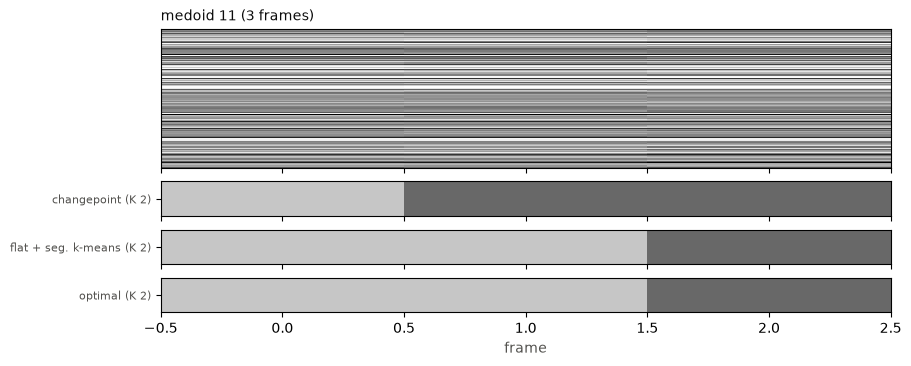

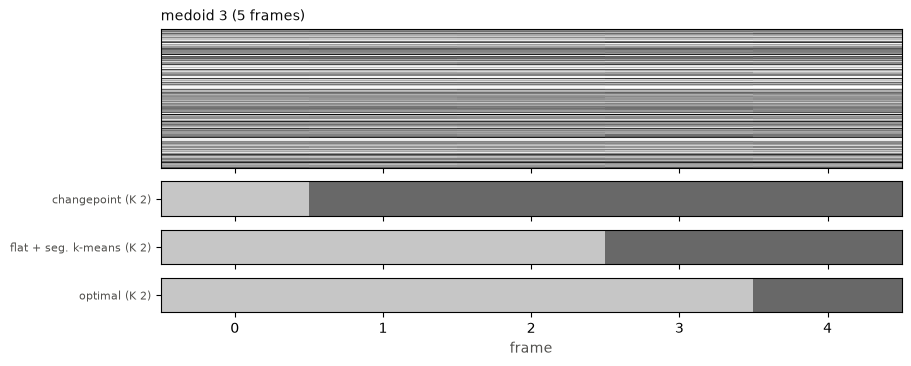

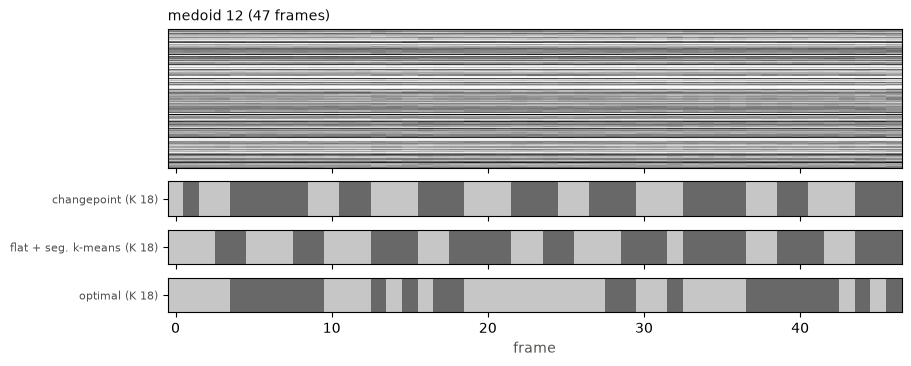

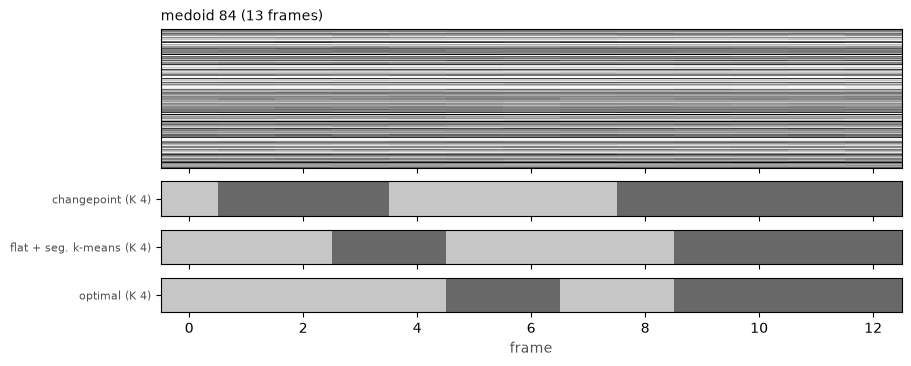

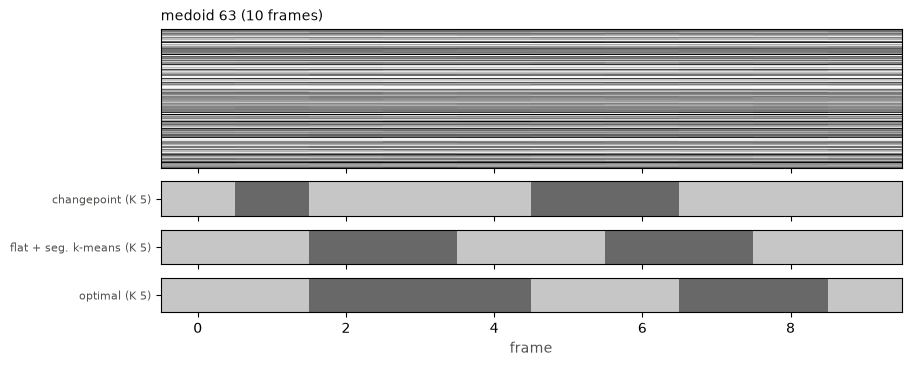

In [8]:
def boundaries(a):
    return np.flatnonzero(np.diff(a) != 0) + 1


def plot_segmentations(index, names_=("changepoint", "flat + seg. k-means", "optimal")):
    seq = np.asarray(medoids[index][0])
    points = top_k_switchpoints(distance_profile(seq), MAX_SWITCHPOINTS)
    fig, axes = plt.subplots(1 + len(names_), 1, figsize=(9, 2.2 + 0.45 * len(names_)), sharex=True,
                             gridspec_kw={'height_ratios': [4] + [1] * len(names_)}, constrained_layout=True)
    axes[0].imshow(seq.T, aspect='auto', cmap='Greys', interpolation='nearest')
    axes[0].set_yticks([])
    axes[0].set_title(f'medoid {index} ({len(seq)} frames)', loc='left', fontsize=10, color='#0b0b0b')
    for ax, name in zip(axes[1:], names_):
        a = INITS[name](seq, points)[0]
        ax.imshow((a % 2)[None, :], aspect='auto', cmap='Greys', vmin=-1, vmax=2, interpolation='nearest')
        backwards = np.flatnonzero(np.diff(a) < 0) + 1
        for b in backwards:
            ax.axvline(b - 0.5, color='#0b0b0b', linewidth=2)
        ax.set_yticks([0])
        ax.set_yticklabels([f"{name} (K {a.max() + 1}{', ' + str(len(backwards)) + ' backward' if len(backwards) else ''})"],
                           fontsize=8, color='#52514e')
    axes[-1].set_xlabel('frame', color='#52514e')
    return fig


def disagreement(i):
    return segmentations["changepoint"]["SSE / frame"][i] - segmentations["optimal"]["SSE / frame"][i]


rng = np.random.default_rng(0)
example_ids = list(np.argsort([-disagreement(i) for i in range(len(medoids))])[:3]) + \
              list(rng.choice(len(medoids), 2, replace=False))
for i in example_ids:
    plot_segmentations(int(i))
    plt.show()

## Build one model per initialization

Same medoids, members, construction and flank settings; only `compress()` is swapped.

In [9]:
models = {}
for name, init in INITS.items():
    with initialization(init):
        models[name], _ = pu.make_hmm([m[0] for m in medoids], [m[2] for m in medoids], MAX_SWITCHPOINTS,
                                      flank_dwell_frames=FLANK_DWELL, flank_alpha=FLANK_ALPHA,
                                      members=members, variance='cluster',
                                      max_members=MAX_MEMBERS, shrinkage=SHRINKAGE)
    print(f"{name}: {len(models[name].pdf)} sub-models, cap {len(models[name].pdf[0])} states")

changepoint: 100 sub-models, cap 23 states


changepoint + seg. k-means: 100 sub-models, cap 23 states
flat: 100 sub-models, cap 23 states


flat + seg. k-means: 100 sub-models, cap 23 states
optimal: 100 sub-models, cap 23 states


flat, max K: 100 sub-models, cap 23 states


## Unseen cluster members

Members past the nearest `max_members` were never used to build their sub-model. Aligned left to right to their own medoid's sub-model (`align_to_states()`, the same alignment construction uses), how well do the states explain them? This is the most direct test of the initialization: same cluster, same alignment, only the states differ. Members shorter than the sub-model can't be aligned and are counted separately.

In [10]:
def submodel_emissions(hmm):
    pdf, last = hmm.pdf, list(hmm.last_match)
    out = []
    for states, n in zip(pdf, last):
        mv = [g.__getstate__() for g in states[1:n + 1]]                # skip the M0 sentinel and the padding
        out.append((np.array([m for m, _ in mv]), np.array([v for _, v in mv])))
    return out


def unseen_member_fit(hmm, max_per_cluster=10):
    emissions = submodel_emissions(hmm)
    ll, frames, too_short, n_members = 0.0, 0, 0, 0
    for (means, variances), cluster in zip(emissions, members):
        for emb, _, _ in cluster[MAX_MEMBERS:MAX_MEMBERS + max_per_cluster]:
            x = np.asarray(emb)
            n_members += 1
            states = pu.align_to_states(x, means, variances)
            if states is None:
                too_short += 1
                continue
            ll += pu._diag_gauss_ll(x, means, variances)[np.arange(len(x)), states].sum()
            frames += len(x)
    return {"unseen members": n_members, "member ll / frame (bits)": ll / frames / np.log(2),
            "members too short": too_short / n_members}


member_fit = pd.DataFrame({name: unseen_member_fit(h) for name, h in models.items()}).T
member_fit.round(3)

,unseen members,member ll / frame (bits),members too short
changepoint,339.0,39.011,0.227
changepoint + seg. k-means,339.0,38.999,0.227
flat,339.0,39.112,0.227
flat + seg. k-means,339.0,39.117,0.227
optimal,339.0,38.895,0.227
"flat, max K",339.0,38.960,0.501


## Downstream: find-style decodes

The same held-out metrics as `ViterbiSubmodelTrainingEffect`, plus sub-model usage of the training exemplars. `saved model` is the production model for reference: it was built from a different clustering that also saw the held-out exemplars, so compare the initializations with `changepoint`, not with it.

In [11]:
def exemplar_rows(hmm):
    decode_hmm = with_search_transitions(hmm)
    return pd.DataFrame([r for part in Parallel(n_jobs=N_JOBS)(delayed(exemplar_eval_batch)(b, decode_hmm, noise_pdf)
                                                               for b in exemplar_batches(heldout_exemplars, N_JOBS * 2))
                         for r in part]).set_index("index").sort_index()


per_exemplar, results = {}, {}
for name, h in {"saved model": saved_hmm, **models}.items():
    n_jobs, chunk_frames = plan_workers(h, N_JOBS)
    rows = exemplar_rows(h)
    per_exemplar[name] = rows
    recordings = evaluate(h, noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)
    usage_ = usage_metrics(exemplar_assignments(h, train_exemplars, n_jobs))
    results[name] = {
        "exemplar_whole": float((rows.largest_cover >= FULL_COVER).mean()),
        "exemplar_hits": float(rows.hits[rows.hits > 0].mean()),
        "exemplar_largest_cover": float(rows.largest_cover.mean()),
        "exemplar_score_per_frame": rows.score.sum() / rows.frames.sum(),
        **{k: recordings[k] for k in ["background_matched", "signal_recall", "whistle_trains_whole",
                                      "hits_per_whistle_train", "hits_per_signal_train"]},
        **{k: usage_[k] for k in ["submodels_used", "top10_share"]},
    }
    print(f"{name}: exemplars whole {results[name]['exemplar_whole']:.3f}, "
          f"whistle trains whole {results[name]['whistle_trains_whole']:.3f}, "
          f"background matched {results[name]['background_matched']:.3f}")

summary = pd.DataFrame(results).T
summary.round(3)

E-step: 4 workers x 4202-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


saved model: exemplars whole 0.642, whistle trains whole 0.084, background matched 0.761
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


changepoint: exemplars whole 0.645, whistle trains whole 0.140, background matched 0.732
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


changepoint + seg. k-means: exemplars whole 0.639, whistle trains whole 0.140, background matched 0.730
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


flat: exemplars whole 0.652, whistle trains whole 0.103, background matched 0.736
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


flat + seg. k-means: exemplars whole 0.635, whistle trains whole 0.121, background matched 0.734
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


optimal: exemplars whole 0.628, whistle trains whole 0.150, background matched 0.736
E-step: 4 workers x 29114-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


flat, max K: exemplars whole 0.628, whistle trains whole 0.131, background matched 0.724


,exemplar_whole,exemplar_hits,exemplar_largest_cover,exemplar_score_per_frame,background_matched,signal_recall,whistle_trains_whole,hits_per_whistle_train,hits_per_signal_train,submodels_used,top10_share
saved model,0.642,1.534,0.801,36.222,0.761,0.940,0.084,3.533,4.433,685.0,0.119
changepoint,0.645,1.534,0.809,34.215,0.732,0.906,0.140,3.206,4.159,100.0,0.626
changepoint + seg. k-means,0.639,1.544,0.805,34.221,0.730,0.904,0.140,3.243,4.209,100.0,0.628
flat,0.652,1.557,0.804,34.190,0.736,0.885,0.103,3.327,4.300,100.0,0.642
flat + seg. k-means,0.635,1.557,0.803,34.189,0.734,0.889,0.121,3.308,4.241,100.0,0.637
optimal,0.628,1.561,0.801,34.199,0.736,0.905,0.150,3.206,4.148,100.0,0.625
"flat, max K",0.628,1.551,0.803,34.072,0.724,0.874,0.131,3.346,4.435,100.0,0.656


### Paired against `changepoint`

The held-out set is small (one split), so per exemplar: how many become whole that weren't under `changepoint`, and how many stop being whole. *p* is a two-sided sign test on those changes.

In [12]:
from scipy.stats import binomtest

base = per_exemplar["changepoint"].largest_cover >= FULL_COVER
paired = {}
for name in models:
    if name == "changepoint":
        continue
    whole = per_exemplar[name].largest_cover >= FULL_COVER
    gained, lost = int((whole & ~base).sum()), int((~whole & base).sum())
    paired[name] = {"gained whole": gained, "lost whole": lost,
                    "p (sign test)": binomtest(gained, gained + lost).pvalue if gained + lost else 1.0,
                    "hits per exemplar Δ": float((per_exemplar[name].hits - per_exemplar["changepoint"].hits).mean())}
pd.DataFrame(paired).T.round(3)

,gained whole,lost whole,p (sign test),hits per exemplar Δ
changepoint + seg. k-means,1.0,3.0,0.625,0.010
flat,10.0,8.0,0.815,0.024
flat + seg. k-means,7.0,10.0,0.629,0.024
optimal,6.0,11.0,0.332,0.027
"flat, max K",11.0,16.0,0.442,0.017
